# EDA for Runs with Metrics

In [134]:
import os

# Print current working directory
print(os.getcwd())

# Change to your desired directory
os.chdir('/Users/svasquez/driblab/dl-vision')
print(os.getcwd())

/Users/svasquez/driblab/dl-vision
/Users/svasquez/driblab/dl-vision


In [135]:
import json
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np

# Load Data

In [136]:
runs_path = f"stats/obso/datasets/filtered_runs.jsonl"


# Load the JSONL file
runs = []
with open(runs_path, 'r') as f:
    for line in f:
        runs.append(json.loads(line))


print(runs[0])
print(f"Run Length: {len(runs)}")

{'match_id': 622555, 'run_id': '622555_14', 'team_id': 12, 'player_id': 1248525, 'ball_carrier_id_start': 189, 'ball_carrier_id_end': 1732978, 'start_frame': 648, 'end_frame': 676, 'start_timestamp': 64.48, 'end_timestamp': 67.28, 'period': 1, 'runner_info': {'start_position': {'x': 70.7, 'y': 51.0}, 'positions': [{'x': 70.7, 'y': 51.0, 'frame': 648, 'period': 1}], 'metrics': {'xR_start': 0.5199999809265137, 'xR_end': 0.7310000061988831, 'PC_start': 0.907, 'PC_end': 0.774, 'xG_start': 0.125, 'xG_end': 0.115, 'OBSO_start': None, 'OBSO_end': None}, 'end_position': {'x': 84.04, 'y': 57.38}}, 'possession': {'start_team': '12', 'end_team': '12'}, 'off_ball_teammates': [{'player_id': 1733126, 'start_position': {'x': 81.32, 'y': 18.96}, 'end_position': {'x': 90.31, 'y': 27.72}, 'metrics': {'xR_start': 0.4269999861717224, 'xR_end': 0.4259999990463257, 'PC_start': 0.601, 'PC_end': 0.534, 'xG_start': 0.088, 'xG_end': 0.134, 'OBSO_start': None, 'OBSO_end': None}}, {'player_id': 1903, 'start_posit

### Load t_player and t_team dfs 

In [137]:
t_player_data = pd.read_csv("/Users/svasquez/AWS_PC/t_player_data.csv")
t_team_data = pd.read_csv("/Users/svasquez/AWS_PC/t_team_data.csv")


## Get unique match ids

In [138]:
match_ids = set()

for run in runs:
    match_ids.add(run['match_id'])

print(match_ids)

print(len(match_ids))



{622593, 622600, 623156, 623157, 623164, 623170, 623178, 622671, 623183, 623185, 638280, 623188, 638281, 628315, 622687, 623200, 623201, 622690, 628323, 628324, 623205, 628326, 622695, 628328, 623209, 623210, 623213, 623215, 623216, 628335, 622708, 622709, 622710, 622711, 623221, 623222, 623225, 622715, 622716, 622717, 622718, 622719, 623226, 622721, 622722, 622723, 622724, 622725, 622726, 622727, 622728, 623229, 622730, 622731, 623240, 622733, 622734, 622735, 622736, 622737, 622738, 622739, 622740, 622741, 622742, 622743, 622744, 622745, 622746, 622747, 622748, 622749, 622750, 622751, 622752, 622753, 622754, 622755, 622756, 623234, 623261, 623262, 623263, 623266, 623267, 623272, 623273, 623275, 623278, 623282, 623283, 623284, 623285, 623286, 623287, 623292, 623299, 623301, 623302, 623304, 623306, 623319, 623321, 623328, 623330, 623331, 623332, 623336, 623337, 623249, 623340, 623344, 623346, 623350, 623351, 623352, 623354, 623355, 623357, 623359, 622849, 623362, 623254, 623363, 623366,

## Get distribution of runs by period

len(periods) 6561

Period frequency:
1    3292
2    3269
dtype: int64


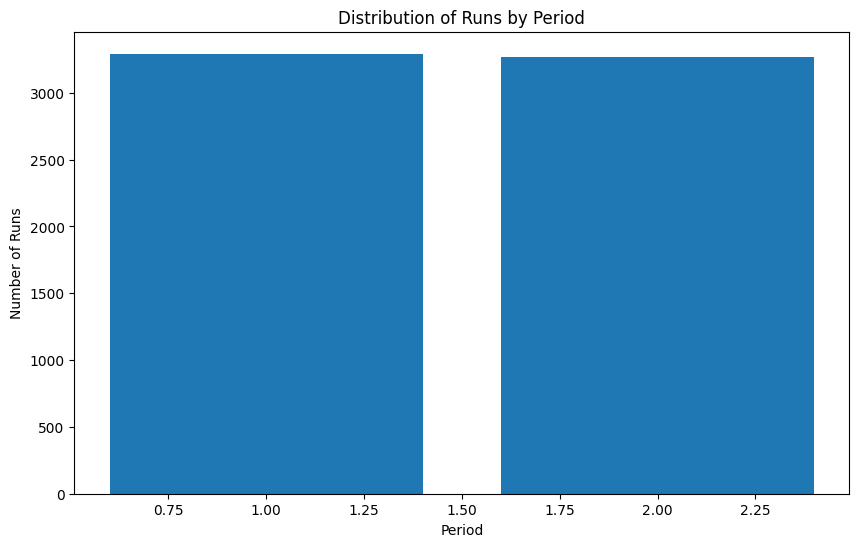

In [141]:
periods = []



for run in runs:
    period = run['period']

    periods.append(period)

print(f"len(periods) {len(periods)}")

# Count frequency of each period
period_counts = pd.Series(periods).value_counts()
print("\nPeriod frequency:")
print(period_counts)

# Plot period distribution
plt.figure(figsize=(10,6))
plt.bar(period_counts.index, period_counts.values)
plt.title('Distribution of Runs by Period')
plt.xlabel('Period')
plt.ylabel('Number of Runs')
plt.show()

# Runner EDA

In [142]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Flatten into a pandas DataFrame
def extract_run_info(run):
    runner = run['runner_info']
    start_x, start_y = runner['start_position']['x'], runner['start_position']['y']
    end_x, end_y = runner['end_position']['x'], runner['end_position']['y']
    dx = end_x - start_x
    dy = end_y - start_y
    distance = (dx**2 + dy**2)**0.5
    duration = run['end_timestamp'] - run['start_timestamp']
    speed = distance / duration if duration > 0 else 0

    return {
        "match_id": run["match_id"],
        "run_id": run["run_id"],
        "team_id": run["team_id"],
        "player_id": run["player_id"],
        "start_frame": run["start_frame"],
        "end_frame": run["end_frame"],
        "duration": duration,
        "distance": distance,
        "speed": speed,
        "period": run["period"],
        "xR_start": runner["metrics"]["xR_start"],
        "xR_end": runner["metrics"]["xR_end"],
        "PC_start": runner["metrics"]["PC_start"],
        "PC_end": runner["metrics"]["PC_end"],
        "xG_start": runner["metrics"]["xG_start"],
        "xG_end": runner["metrics"]["xG_end"],
    }



df = pd.DataFrame([extract_run_info(r) for r in runs])
# df = pd.DataFrame([extract_run_info(r) for r in filtered_runs])

print(f"LENGTH: {len(df)}")

# --- BASIC STATS ---
print("\n📊 General Stats")
print(df.describe())



LENGTH: 6561

📊 General Stats
            match_id        team_id     player_id   start_frame     end_frame  \
count    6561.000000    6561.000000  6.561000e+03   6561.000000   6561.000000   
mean   623941.158055   10704.815424  1.031966e+06  28392.162780  28416.969517   
std      4165.764098   23585.170904  5.093007e+05  17076.367671  17076.701018   
min    622555.000000       9.000000  3.400000e+01     52.000000     72.000000   
25%    622984.000000    1928.000000  1.156118e+06  13524.000000  13546.000000   
50%    623263.000000    1940.000000  1.171222e+06  28230.000000  28248.000000   
75%    623377.000000    3653.000000  1.302202e+06  42810.000000  42828.000000   
max    666385.000000  172400.000000  2.061871e+06  63492.000000  63508.000000   

          duration     distance        speed       period     xR_start  \
count  6561.000000  6561.000000  6561.000000  6561.000000  6561.000000   
mean      2.475725    13.405353     6.268436     1.498247     0.447444   
std       2.147390

In [143]:


# Group by 'player_id' and count runs
run_counts = df.groupby('player_id')['run_id'].count().reset_index(name='run_count')

# Sort by run count
run_counts = run_counts.sort_values(by='run_count', ascending=False)

# Merge with player data
run_counts = run_counts.merge(t_player_data, on='player_id', how='left')

run_counts.head(10)


,player_id,run_count,name,team_id
0,40942,44,Jamie Vardy,2053
1,1304410,42,Kaoru Mitoma,2019
2,1158581,41,Kai Havertz,1928
3,1159814,39,Leandro Trossard,1928
4,1163669,38,Erling Haaland,1939
5,1427943,37,Daniel Muñoz,1938
6,166831,36,Raul Jimenez,1933
7,1295026,35,Martinelli,1928
8,1165587,35,Antonee Robinson,1933
9,357,34,Mohamed Salah,1926


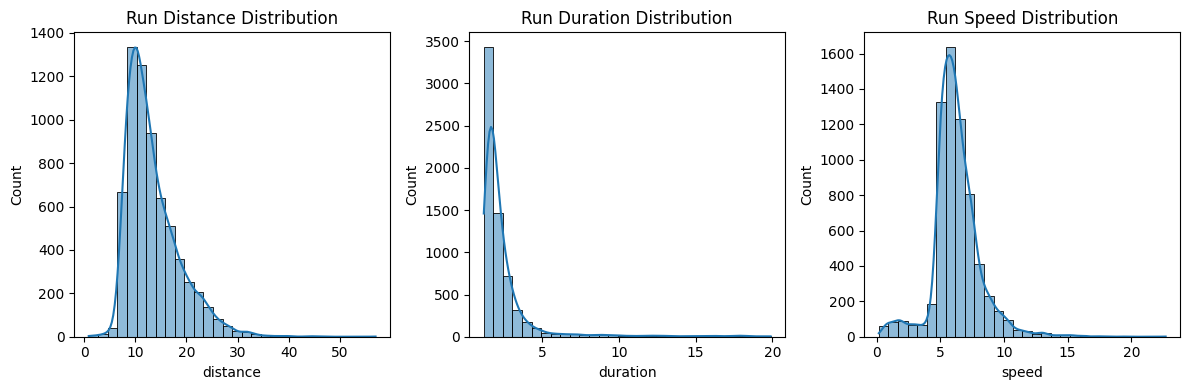

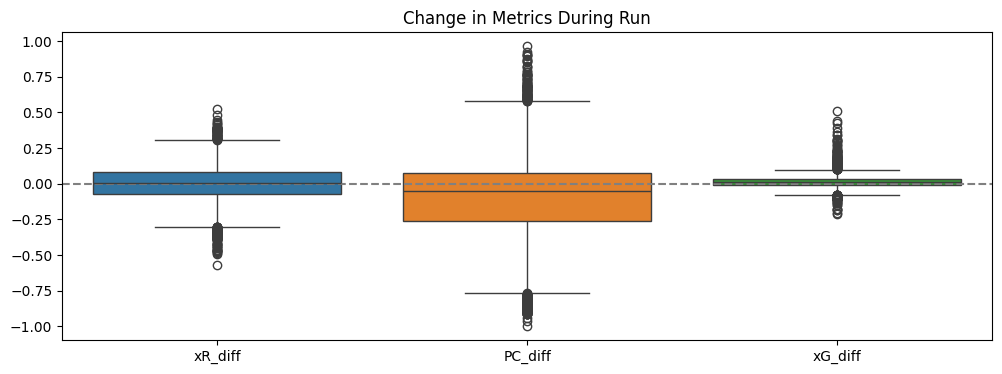

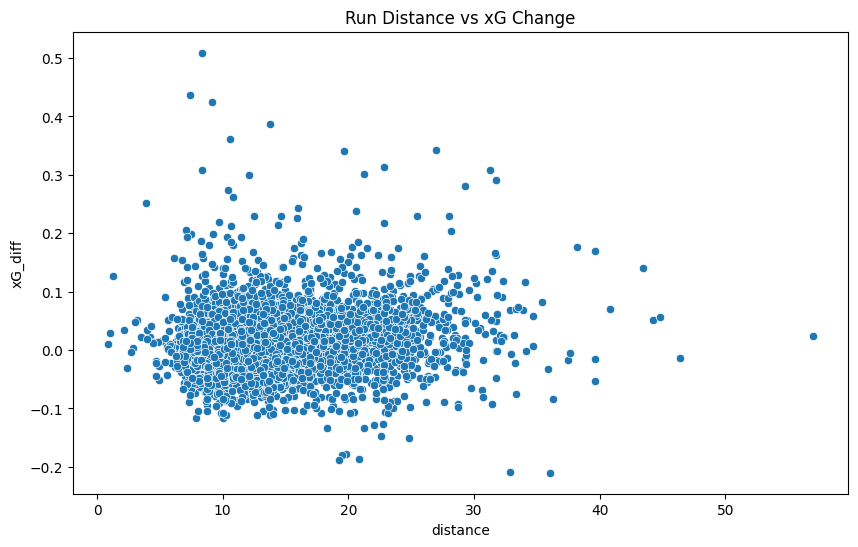

In [145]:

# --- DISTRIBUTIONS ---
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
sns.histplot(df["distance"], bins=30, kde=True)
plt.title("Run Distance Distribution")

plt.subplot(1, 3, 2)
sns.histplot(df["duration"], bins=30, kde=True)
plt.title("Run Duration Distribution")

plt.subplot(1, 3, 3)
sns.histplot(df["speed"], bins=30, kde=True)
plt.title("Run Speed Distribution")

plt.tight_layout()
plt.show()

# --- METRIC CHANGE DURING RUN ---
df["xR_diff"] = df["xR_end"] - df["xR_start"]
df["PC_diff"] = df["PC_end"] - df["PC_start"]
df["xG_diff"] = df["xG_end"] - df["xG_start"]

plt.figure(figsize=(12, 4))
sns.boxplot(data=df[["xR_diff", "PC_diff", "xG_diff"]])
plt.title("Change in Metrics During Run")
plt.axhline(0, color="gray", linestyle="--")
plt.show()

# --- SCATTERPLOTS ---
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="distance", y="xG_diff")
plt.title("Run Distance vs xG Change")
plt.show()

# # Optional: save for manual analysis
# df.to_csv("run_eda_summary.csv", index=False)


## Get the top run with runner's change in xG, xR and PC

In [146]:
# Calculate total changes for each metric
df["xR_added_runner"] = df["xR_end"] - df["xR_start"]
df["PC_added_runner"] = df["PC_end"] - df["PC_start"] 
df["xG_added_runner"] = df["xG_end"] - df["xG_start"]
df['OBSO_start'] = df['xR_start'] * df['PC_start'] * df['xG_start']
df['OBSO_end'] = df['xR_end'] * df['PC_end'] * df['xG_end']
df['OBSO_added'] = df['OBSO_end'] - df['OBSO_start']

df

,match_id,run_id,team_id,player_id,start_frame,end_frame,duration,distance,speed,period,...,xG_end,xR_diff,PC_diff,xG_diff,xR_added_runner,PC_added_runner,xG_added_runner,OBSO_start,OBSO_end,OBSO_added
0,622555,622555_14,12,1248525,648,676,2.8,14.787157,5.281127,1,...,0.115,0.211,-0.133,-0.010,0.211,-0.133,-0.010,0.058955,0.065066,0.006111
1,622555,622555_15,12,1281301,668,686,1.8,10.339516,5.744176,1,...,0.115,-0.194,-0.182,-0.016,-0.194,-0.182,-0.016,0.042789,0.016181,-0.026609
2,622555,622555_17,12,1304950,744,760,1.6,7.702110,4.813819,1,...,0.150,0.178,-0.126,0.063,0.178,-0.126,0.063,0.017555,0.032500,0.014945
3,622555,622555_39,12,1733126,3452,3466,1.4,10.773138,7.695098,1,...,0.095,-0.135,-0.188,-0.013,-0.135,-0.188,-0.013,0.027318,0.011218,-0.016101
4,622555,622555_41,12,1732978,3462,3486,2.4,22.610440,9.421017,1,...,0.103,0.164,0.179,0.011,0.164,0.179,0.011,0.026389,0.051626,0.025237
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6556,666385,666385_404,3651,1329659,51920,51962,4.2,16.083345,3.829368,2,...,0.116,0.048,-0.309,0.004,0.048,-0.309,0.004,0.026844,0.021401,-0.005443
6557,666385,666385_432,3651,69700,54954,54968,1.4,7.097443,5.069602,2,...,0.080,-0.216,-0.073,0.015,-0.216,-0.073,0.015,0.021267,0.013071,-0.008195
6558,666385,666385_436,3659,1322737,55386,55406,2.0,13.996017,6.998009,2,...,0.097,0.117,0.063,0.030,0.117,0.063,0.030,0.010335,0.023207,0.012872
6559,666385,666385_437,3659,1159149,55388,55408,2.0,12.034471,6.017236,2,...,0.085,-0.060,-0.175,-0.018,-0.060,-0.175,-0.018,0.032268,0.017746,-0.014522


In [147]:
mean_xR = df['xR_added_runner'].mean()
mean_PC = df['PC_added_runner'].mean()
mean_xG = df['xG_added_runner'].mean()

print(f"Mean xR: {mean_xR}")
print(f"Mean PC: {mean_PC}")
print(f"Mean xG: {mean_xG}")

Mean xR: -2.636800786558947e-05
Mean PC: -0.0874256973022405
Mean xG: 0.011677030940405425


## Test Correlation between xR and PC

Correlation between xR and PC: 0.110
Correlation between xR and xG: 0.081
Correlation between PC and xG: 0.345


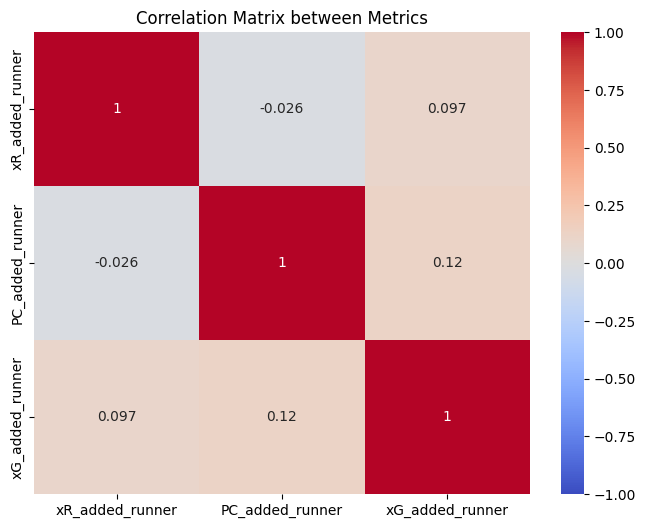

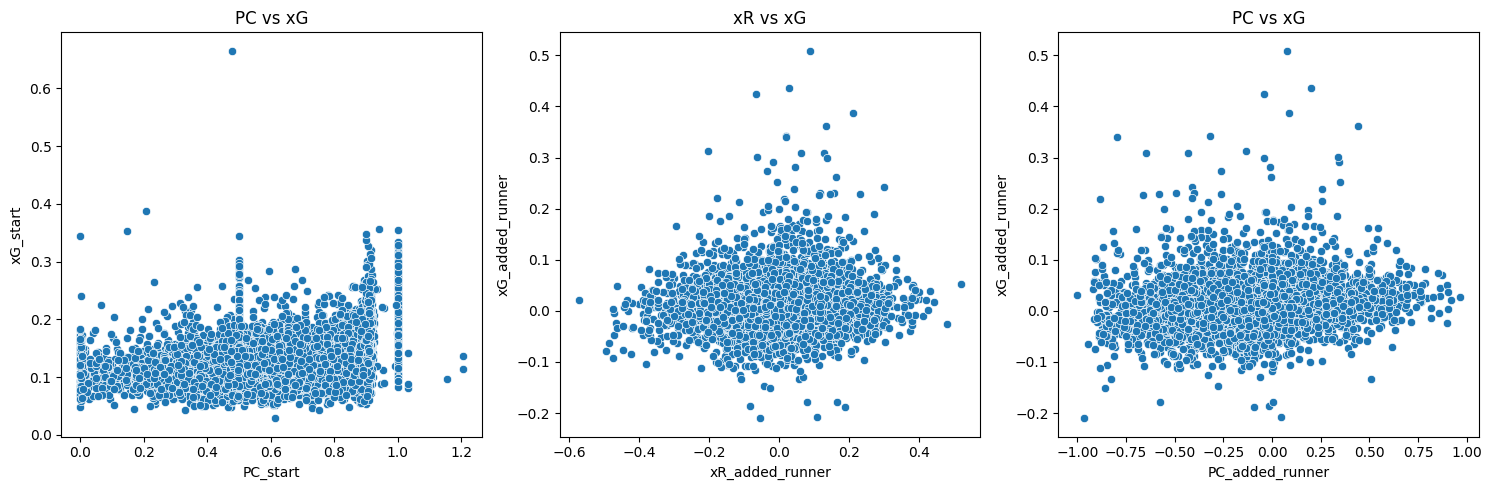

In [148]:
# Calculate correlations between metrics
corr_xR_PC = df['xR_start'].corr(df['PC_start'])
corr_xR_xG = df['xR_start'].corr(df['xG_start']) 
corr_PC_xG = df['PC_start'].corr(df['xG_start'])

print(f"Correlation between xR and PC: {corr_xR_PC:.3f}")
print(f"Correlation between xR and xG: {corr_xR_xG:.3f}")
print(f"Correlation between PC and xG: {corr_PC_xG:.3f}")

# Create correlation matrix plot
plt.figure(figsize=(8, 6))
corr_matrix = df[['xR_added_runner', 'PC_added_runner', 'xG_added_runner']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Correlation Matrix between Metrics")
plt.show()

# Create scatter plots
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.scatterplot(data=df, x='PC_start', y='xG_start', ax=axes[0])
axes[0].set_title('PC vs xG')

sns.scatterplot(data=df, x='xR_added_runner', y='xG_added_runner', ax=axes[1])
axes[1].set_title('xR vs xG')

sns.scatterplot(data=df, x='PC_added_runner', y='xG_added_runner', ax=axes[2])
axes[2].set_title('PC vs xG')

plt.tight_layout()
plt.show()


# Top run with more OBSO

In [149]:
df.nlargest(10, "OBSO_added")

,match_id,run_id,team_id,player_id,start_frame,end_frame,duration,distance,speed,period,...,xG_end,xR_diff,PC_diff,xG_diff,xR_added_runner,PC_added_runner,xG_added_runner,OBSO_start,OBSO_end,OBSO_added
2856,623221,623221_205,1946,158802,29658,29833,17.50,13.730623,0.784607,2,...,0.599,0.211,0.085,0.387,0.211,0.085,0.387,0.074601,0.356647,0.282046
21,622555,622555_223,12,1453339,22480,22496,1.60,10.585613,6.616008,1,...,0.479,0.133,0.444,0.362,0.133,0.444,0.362,0.022243,0.236937,0.214694
912,622738,622738_419,37,39006,56542,56556,1.40,31.765115,22.689368,2,...,0.414,-0.018,0.345,0.291,-0.018,0.345,0.291,0.031867,0.166346,0.134479
5242,623399,623399_329,1948,40828,45802,45988,18.36,21.258231,1.157856,2,...,0.415,-0.065,0.337,0.301,-0.065,0.337,0.301,0.029222,0.156880,0.127658
2855,623221,623221_164,1946,258141,25546,25566,2.00,11.610004,5.805002,1,...,0.251,0.235,0.573,0.044,0.235,0.573,0.044,0.027435,0.143948,0.116513
5164,623396,623396_327,1946,258141,49708,49728,2.00,18.451312,9.225656,2,...,0.252,0.174,0.503,0.068,0.174,0.503,0.068,0.032883,0.146332,0.113449
1653,622984,622984_337,3653,240769,44840,44934,9.28,31.841534,3.431200,2,...,0.242,0.152,0.346,0.094,0.152,0.346,0.094,0.048827,0.158918,0.110091
5870,623431,623431_241,2019,1304410,31624,31684,6.00,31.405694,5.234282,2,...,0.243,0.181,0.147,0.135,0.181,0.147,0.135,0.037138,0.139867,0.102730
1980,623066,623066_77,3660,69856,15232,15296,6.40,19.639898,3.068734,1,...,0.217,0.179,0.095,0.132,0.179,0.095,0.132,0.034040,0.134839,0.100799
3163,623256,623256_105,1932,1157172,19336,19350,1.42,13.230306,9.317117,1,...,0.266,0.117,0.618,0.043,0.117,0.618,0.043,0.026165,0.126180,0.100015


In [150]:

# Sort by each metric and get top 5
print("\nTop 5 runs by xR added for runner:")
print(df.nlargest(5, "xR_added_runner")[["match_id", "run_id", "team_id", "period", "xR_added_runner", "PC_added_runner", "xG_added_runner"]])

print("\nTop 5 runs by PC added for runner:")
print(df.nlargest(5, "PC_added_runner")[["match_id", "run_id", "team_id", "period", "xR_added_runner", "PC_added_runner", "xG_added_runner"]])

print("\nTop 5 runs by xG added for runner:")
print(df.nlargest(5, "xG_added_runner")[["match_id", "run_id", "team_id", "period", "xR_added_runner", "PC_added_runner", "xG_added_runner"]])



Top 5 runs by xR added for runner:
      match_id      run_id  team_id  period  xR_added_runner  PC_added_runner  \
5531    623417  623417_468     2068       2            0.520           -0.226   
2409    623170  623170_453     1946       2            0.478           -0.514   
1407    622755  622755_189       46       1            0.443           -0.326   
4635    623359   623359_52     1928       1            0.430           -0.164   
5180    623397   623397_78     1943       1            0.425           -0.300   

      xG_added_runner  
5531            0.052  
2409           -0.025  
1407            0.018  
4635            0.039  
5180            0.001  

Top 5 runs by PC added for runner:
      match_id      run_id  team_id  period  xR_added_runner  PC_added_runner  \
4484    623351  623351_221     1940       1           -0.102            0.964   
685     622728  622728_301       18       2           -0.261            0.921   
6527    666385   666385_70     3651       1           

# Team Wide Runs EDA

In [ ]:
import json
import pandas as pd


# Create a DataFrame to hold team-wide deltas
rows = []

for run in runs:
    run_id = run['run_id']
    match_id = run['match_id']
    period = run['period']
    team_id = run['team_id']

    sum_xR_delta = 0
    sum_PC_delta = 0
    sum_xG_delta = 0

    for teammate in run.get('off_ball_teammates', []):
        metrics = teammate.get('metrics', {})
        xR_start = metrics.get('xR_start', 0) or 0
        xR_end = metrics.get('xR_end', 0) or 0
        PC_start = metrics.get('PC_start', 0) or 0
        PC_end = metrics.get('PC_end', 0) or 0
        xG_start = metrics.get('xG_start', 0) or 0
        xG_end = metrics.get('xG_end', 0) or 0

        sum_xR_delta += xR_end - xR_start
        sum_PC_delta += PC_end - PC_start
        sum_xG_delta += xG_end - xG_start

    rows.append({
        "match_id": match_id,
        "run_id": run_id,
        "team_id": team_id,
        "period": period,
        "xR_added_team": sum_xR_delta,
        "PC_added_team": sum_PC_delta,
        "xG_added_team": sum_xG_delta
    })

df = pd.DataFrame(rows)
df

,match_id,run_id,team_id,period,xR_added_team,PC_added_team,xG_added_team
0,622555,622555_14,12,1,0.428,-2.116,0.041
1,622555,622555_15,12,1,-0.667,-0.015,0.065
2,622555,622555_17,12,1,-0.087,-0.600,0.134
3,622555,622555_39,12,1,-0.312,0.073,0.089
4,622555,622555_41,12,1,-0.572,-0.472,0.139
...,...,...,...,...,...,...,...
6556,666385,666385_404,3651,2,-0.590,0.544,0.091
6557,666385,666385_432,3651,2,-0.519,0.543,-0.073
6558,666385,666385_436,3659,2,0.080,0.135,-0.059
6559,666385,666385_437,3659,2,0.597,-1.120,-0.010


In [152]:

print("\n📊 Basic stats per metric:")
print(df[["xR_added_team", "PC_added_team", "xG_added_team"]].describe())




📊 Basic stats per metric:
       xR_added_team  PC_added_team  xG_added_team
count    6561.000000    6561.000000    6561.000000
mean       -0.050439       0.066672       0.037790
std         0.475852       0.875251       0.117612
min        -2.711000      -4.029000      -0.968000
25%        -0.318000      -0.466000      -0.029000
50%        -0.044000       0.047000       0.030000
75%         0.221000       0.585000       0.094000
max         1.973000       4.632000       1.712000


In [153]:
print("\n📈 Top 5 runs by team xR added:")
top_runs = df.sort_values(by="xR_added_team", ascending=False).head()
top_runs




📈 Top 5 runs by team xR added:


,match_id,run_id,team_id,period,xR_added_team,PC_added_team,xG_added_team
3604,623284,623284_188,1926,1,1.973,2.741,0.020
5630,623422,623422_849,1932,2,1.964,0.902,-0.003
5129,623395,623395_421,1933,2,1.930,0.450,0.003
1638,622984,622984_131,3653,1,1.898,-0.256,0.324
4038,623328,623328_950,1926,2,1.888,-1.063,-0.017


In [154]:
print("\n📈 Top 5 runs by team PC added:")
top_runs = df.sort_values(by="PC_added_team", ascending=False).head()
top_runs


📈 Top 5 runs by team PC added:


,match_id,run_id,team_id,period,xR_added_team,PC_added_team,xG_added_team
801,622734,622734_525,64219,2,-0.402,4.632,1.712
904,622738,622738_396,37,2,-0.572,4.556,0.275
6270,628323,628323_377,63681,2,-0.563,4.190,0.311
2565,623188,623188_422,1933,2,-0.120,4.147,0.266
905,622738,622738_397,37,2,-0.486,4.084,0.227


In [155]:
print("\n📈 Top 5 runs by team xG added:")
top_runs = df.sort_values(by="xG_added_team", ascending=False).head()
top_runs


📈 Top 5 runs by team xG added:


,match_id,run_id,team_id,period,xR_added_team,PC_added_team,xG_added_team
801,622734,622734_525,64219,2,-0.402,4.632,1.712
1372,622752,622752_493,16,2,-0.486,-0.829,1.037
5359,623411,623411_19,1930,1,-0.334,0.104,0.956
4145,623332,623332_205,1928,1,-0.959,1.288,0.904
5241,623399,623399_328,1948,2,-0.444,0.883,0.868


# Plot Runs

In [34]:
from stats.obso.run_detection.plot_run import PlotRun
match_id = 622593
    
pr = PlotRun(match_id)

pr.load_pitch_control()



FileNotFoundError: [Errno 2] No such file or directory: 'outputs/622593/622593_runs.jsonl'

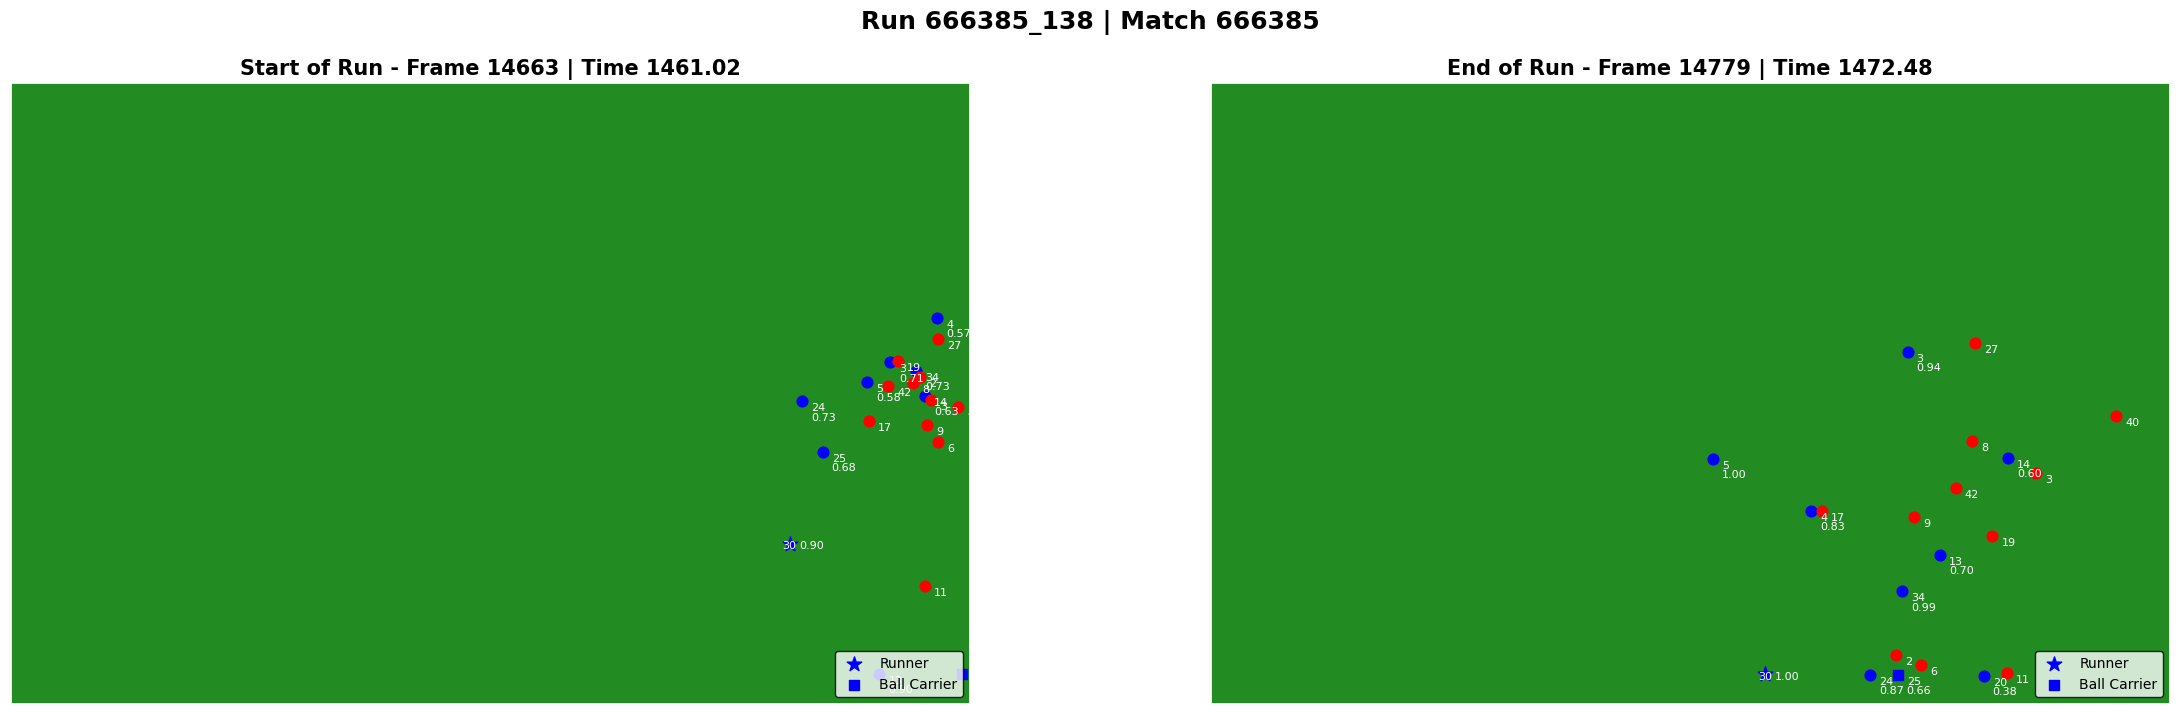

In [35]:


run_id = 138
fig = pr.plot_run(pr.runs[run_id], pr.player_lookup, pc_annotate = True, def_team = True)
plt.show()

# Calculate Raw OBSO

In [161]:
def calc_raw_obso(xR, PC, xG):
    return xR * PC * (xG **1)



team_wide_obso = []
for run in runs:

    team_wide_OBSO_start = 0
    team_wide_OBSO_end = 0

    # Calculate raw OBSO for runner
    runner_OBSO_start = calc_raw_obso(run['runner_info']['metrics']['xR_start'], run['runner_info']['metrics']['PC_start'], run['runner_info']['metrics']['xG_start'])
    runner_OBSO_end = calc_raw_obso(run['runner_info']['metrics']['xR_end'], run['runner_info']['metrics']['PC_end'], run['runner_info']['metrics']['xG_end'])

    team_wide_OBSO_start += runner_OBSO_start
    team_wide_OBSO_end += runner_OBSO_end

    run['runner_info']['metrics']['OBSO_start'] = runner_OBSO_start
    run['runner_info']['metrics']['OBSO_end'] = runner_OBSO_end
    run['runner_info']['metrics']['OBSO_delta'] = runner_OBSO_end - runner_OBSO_start

    # Calculate raw OBSO for all teammates
    for teammate in run['off_ball_teammates']:
        teammate_OBSO_start = calc_raw_obso(teammate['metrics']['xR_start'], teammate['metrics']['PC_start'], teammate['metrics']['xG_start'])
        teammate_OBSO_end = calc_raw_obso(teammate['metrics']['xR_end'], teammate['metrics']['PC_end'], teammate['metrics']['xG_end'])
        teammate_OBSO_delta = teammate_OBSO_end - teammate_OBSO_start

        teammate['metrics']['OBSO_start'] = teammate_OBSO_start
        teammate['metrics']['OBSO_end'] = teammate_OBSO_end
        teammate['metrics']['OBSO_delta'] = teammate_OBSO_delta

        team_wide_OBSO_start += teammate_OBSO_start
        team_wide_OBSO_end += teammate_OBSO_end

    run['team_wide_OBSO_start'] = team_wide_OBSO_start
    run['team_wide_OBSO_end'] = team_wide_OBSO_end

    team_wide_OBSO_delta = team_wide_OBSO_end - team_wide_OBSO_start
    run['team_wide_OBSO_delta'] = team_wide_OBSO_delta

    team_wide_obso.append({
        'match_id': run['match_id'],
        'run_id': run['run_id'],
        'team_id': run['team_id'],
        'OBSO_delta': team_wide_OBSO_delta
    })



In [162]:
# Get average OBSO metrics
avg_team_wide_obso = pd.DataFrame(team_wide_obso)
avg_team_wide_obso['OBSO_delta'].mean()



0.009051036085032408

## Get teh average OBSO metrics

In [180]:
# Make DF of OBSO metrics
obso_metrics = []

for run in runs:
    # Get runner metrics
    runner_metrics = {
        'match_id': run['match_id'],
        'run_id': run['run_id'],
        'team_id': run['team_id'],
        'player_id': run['player_id'],
        'start_frame': run['start_frame'],
        'end_frame': run['end_frame'],
        'period': run['period'],
        'is_runner': True,
        'team_wide_OBSO_delta' : run['team_wide_OBSO_delta']

    }
    obso_metrics.append(runner_metrics)
    
# Convert to DataFrame
obso_df = pd.DataFrame(obso_metrics)

obso_df = obso_df.sort_values(by='team_wide_OBSO_delta', ascending=False)
obso_df

,match_id,run_id,team_id,player_id,start_frame,end_frame,period,is_runner,team_wide_OBSO_delta
801,622734,622734_525,64219,1221243,58600,58647,2,True,1.618267
6270,628323,628323_377,63681,1165584,41814,41925,2,True,0.632566
3604,623284,623284_188,1926,1247852,26328,26453,1,True,0.532908
2131,623073,623073_325,63957,247690,34132,34152,2,True,0.511552
4257,623337,623337_160,1930,1155313,11390,11475,1,True,0.485929
...,...,...,...,...,...,...,...,...,...
135,622687,622687_37,62071,1710198,3234,3260,1,True,-0.371099
6370,638279,638279_184,1936,1262750,27478,27549,1,True,-0.379430
4037,623328,623328_946,1926,1167845,55120,55138,2,True,-0.449846
6507,638295,638295_230,3662,1170503,41368,41398,2,True,-0.460087


In [174]:
# Grouping by 'player_id' and summing 'team_wide_OBSO_delta'
grouped_df = obso_df.groupby('player_id')['team_wide_OBSO_delta'].mean().reset_index()

# Sort by team_wide_OBSO_delta
grouped_df = grouped_df.sort_values(by='team_wide_OBSO_delta', ascending=False)


# Join with t_player_data
t_player_data = pd.read_csv("/Users/svasquez/AWS_PC/t_player_data.csv")

grouped_df = grouped_df.merge(t_player_data, on='player_id', how='left')

# Merge with run counts

grouped_df = grouped_df.merge(run_counts, on='player_id', how='left')

# get onoy playes that have at least 10 runs
grouped_df = grouped_df[grouped_df['run_count'] >= 10]

grouped_df.head(20)


,player_id,team_wide_OBSO_delta,name_x,team_id_x,run_count,name_y,team_id_y
33,1300227,0.135110,Malo Gusto,1930,11,Malo Gusto,1930
91,1301778,0.087100,Levi Colwill,1930,14,Levi Colwill,1930
120,1740257,0.075353,Carlos Baleba,2019,17,Carlos Baleba,2019
133,38908,0.071904,Romelu Lukaku,34,10,Romelu Lukaku,34
152,1242415,0.062780,Jan Paul Van Hecke,2019,12,Jan Paul Van Hecke,2019
164,41349,0.059590,Dan Burn,1932,17,Dan Burn,1932
176,1708749,0.056442,Jack Hinshelwood,2019,19,Jack Hinshelwood,2019
177,1156421,0.056393,Vladimir Coufal,1948,13,Vladimir Coufal,1948
185,94366,0.054524,Mateo Kovacic,1939,12,Mateo Kovacic,1939
191,1313600,0.052454,Lewis Hall,1932,14,Lewis Hall,1932


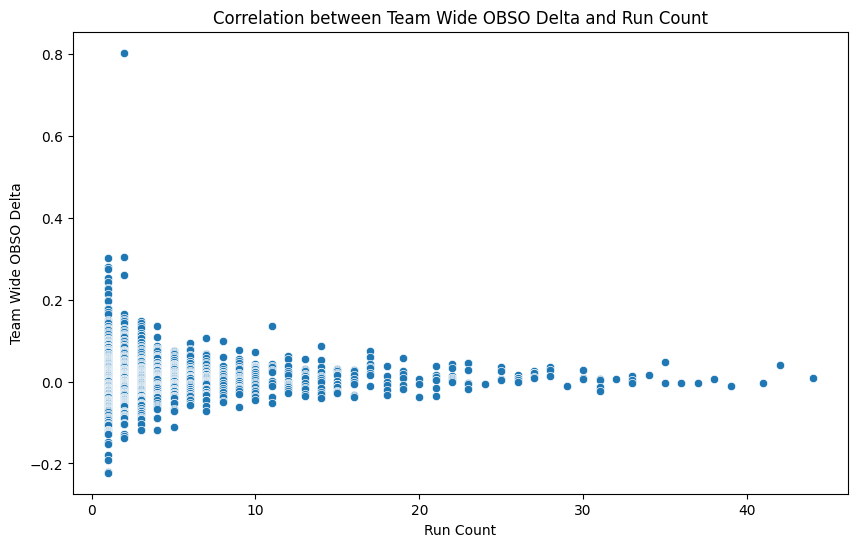

In [173]:
# plot corr between team_wide_OBSO_delta and run_count
plt.figure(figsize=(10, 6))
sns.scatterplot(data=grouped_df, x='run_count', y='team_wide_OBSO_delta')
plt.title('Correlation between Team Wide OBSO Delta and Run Count')
plt.xlabel('Run Count')
plt.ylabel('Team Wide OBSO Delta')
plt.show()

## Get the OBSO delta by Runner

In [177]:
# Make DF of OBSO metrics
obso_metrics_runner = []

for run in runs:
    

    
    # Get runner metrics
    runner_metrics = {
        'match_id': run['match_id'],
        'run_id': run['run_id'],
        'team_id': run['team_id'],
        'player_id': run['player_id'],
        'start_frame': run['start_frame'],
        'end_frame': run['end_frame'],
        'period': run['period'],
        'is_runner': True,
        'OBSO_delta' : run['runner_info']['metrics']['OBSO_delta']

    }
    obso_metrics_runner.append(runner_metrics)
    
# Convert to DataFrame
obso_runner_df = pd.DataFrame(obso_metrics_runner)
obso_runner_df

,match_id,run_id,team_id,player_id,start_frame,end_frame,period,is_runner,OBSO_delta
0,622555,622555_14,12,1248525,648,676,1,True,0.006111
1,622555,622555_15,12,1281301,668,686,1,True,-0.026609
2,622555,622555_17,12,1304950,744,760,1,True,0.014945
3,622555,622555_39,12,1733126,3452,3466,1,True,-0.016101
4,622555,622555_41,12,1732978,3462,3486,1,True,0.025237
...,...,...,...,...,...,...,...,...,...
6556,666385,666385_404,3651,1329659,51920,51962,2,True,-0.005443
6557,666385,666385_432,3651,69700,54954,54968,2,True,-0.008195
6558,666385,666385_436,3659,1322737,55386,55406,2,True,0.012872
6559,666385,666385_437,3659,1159149,55388,55408,2,True,-0.014522


In [179]:
# Grouping by 'player_id' and summing 'team_wide_OBSO_delta'
grouped_df_runner = obso_runner_df.groupby('player_id')['OBSO_delta'].sum().reset_index()

# Sort by team_wide_OBSO_delta
grouped_df_runner = grouped_df_runner.sort_values(by='OBSO_delta', ascending=False)


# Join with t_player_data
t_player_data = pd.read_csv("/Users/svasquez/AWS_PC/t_player_data.csv")

grouped_df_runner = grouped_df_runner.merge(t_player_data, on='player_id', how='left')

# Merge with run counts

grouped_df_runner = grouped_df_runner.merge(run_counts, on='player_id', how='left')

# get onoy playes that have at least 10 runs
grouped_df_runner = grouped_df_runner[grouped_df_runner['run_count'] >= 10]

grouped_df_runner.head(20)

,player_id,OBSO_delta,name_x,team_id_x,run_count,name_y,team_id_y
1,1242415,0.296074,Jan Paul Van Hecke,2019,12,Jan Paul Van Hecke,2019
2,41349,0.257204,Dan Burn,1932,17,Dan Burn,1932
3,1301778,0.255186,Levi Colwill,1930,14,Levi Colwill,1930
5,1155313,0.226165,Christopher Nkunku,1930,22,Christopher Nkunku,1930
6,1157172,0.215298,Alexander Isak,1932,22,Alexander Isak,1932
8,240037,0.198506,Fabian Schar,1932,15,Fabian Schar,1932
19,1295026,0.133448,Martinelli,1928,35,Martinelli,1928
20,138606,0.130819,Bernardo Silva,1939,30,Bernardo Silva,1939
21,1158367,0.121711,Aaron Wan Bissaka,1948,10,Aaron Wan Bissaka,1948
22,1619221,0.119149,Kobbie Mainoo,1946,13,Kobbie Mainoo,1946
